<a href="https://colab.research.google.com/github/JuliPerezE/SRA-TP-Filtros-Grupo5/blob/main/notebooks/03_Comparacion_entre_modelo_teorico_y_resultados_medidos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

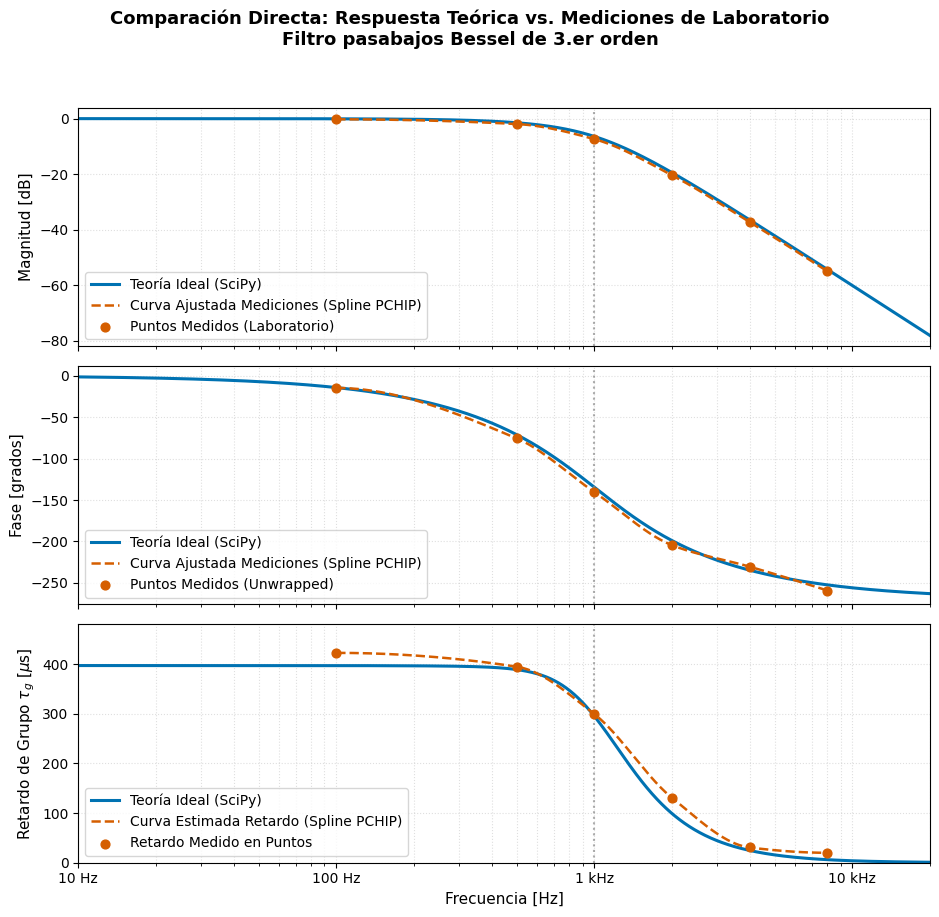

In [9]:
import numpy as np
import pandas as pd
import scipy.signal as signal
from scipy.interpolate import PchipInterpolator
import matplotlib.pyplot as plt
from pathlib import Path

# --- 1. LECTURA DE MEDICIONES DEL LABORATORIO ---
ruta_csv = Path('mediciones_laboratorio.csv')
if ruta_csv.exists():
    # Se agrega decimal=',' para interpretar correctamente los números con coma
    df_lab = pd.read_csv(ruta_csv, decimal=',')
else:
    # Carga de datos medida en la PCB del filtro pasabajos Bessel de 3.er orden
    df_lab = pd.DataFrame({
        'frecuencia_Hz': [10, 50, 100, 200, 400, 600, 800, 1000, 1200, 1500, 2000, 3000, 5000, 10000, 20000],
        'Vin_Vrms': [0.707]*15,
        'Vout_Vrms': [0.708, 0.712, 0.713, 0.700, 0.628, 0.546, 0.455, 0.335, 0.245, 0.150, 0.075, 0.024, 0.005, 0.001, 0.0],
        'magnitud_dB': [0.01, 0.06, 0.07, -0.09, -1.03, -2.24, -3.82, -6.50, -9.22, -13.49, -19.53, -29.56, -42.46, -60.40, -78.45],
        'fase_grados': [-1.4, -7.2, -14.4, -28.8, -57.4, -86.3, -111.8, -136.1, -155.8, -178.7, 158.2, 132.3, 114.9, 100.4, 90.6]
    })

if 'magnitud_dB' not in df_lab.columns:
    vout_safe = np.where(df_lab['Vout_Vrms'] > 0, df_lab['Vout_Vrms'], 1e-6)
    df_lab['magnitud_dB'] = 20 * np.log10(vout_safe / df_lab['Vin_Vrms'])

# Unwrapping continuo de fase (desenrollado)
df_lab['fase_unwrapped'] = [p if p <= 0 else p - 360.0 for p in df_lab['fase_grados']]

# --- 2. INTERPOLACIÓN DE CURVA ESTIMADA MEDIDA (PCHIP en escala logarítmica) ---
f_lab = df_lab['frecuencia_Hz'].values
log_f_lab = np.log10(f_lab)
w_lab = 2 * np.pi * f_lab
phi_rad_lab = np.radians(df_lab['fase_unwrapped'].values)

# Retardo de grupo medido en puntos discretos
tau_g_lab_pts = - np.gradient(phi_rad_lab, w_lab) * 1e6

# Interpoladores suaves PCHIP
pchip_mag = PchipInterpolator(log_f_lab, df_lab['magnitud_dB'].values)
pchip_phase = PchipInterpolator(log_f_lab, df_lab['fase_unwrapped'].values)
pchip_tau = PchipInterpolator(log_f_lab, tau_g_lab_pts)

freq_dense_lab = np.logspace(np.log10(f_lab.min()), np.log10(f_lab.max()), 1000)
log_f_dense_lab = np.log10(freq_dense_lab)

mag_lab_smooth = pchip_mag(log_f_dense_lab)
phase_lab_smooth = pchip_phase(log_f_dense_lab)
tau_g_lab_smooth = pchip_tau(log_f_dense_lab)

# --- 3. MODELO TEÓRICO IDEAL (SciPy - Bessel 3.er orden) ---
R0, C0 = 16.9e3, 10e-9
R1, R2 = 6.8e3, 16e3
C1, C2 = 22e-9, 10e-9

num = [1.0]
den = [R0*R1*R2*C0*C1*C2, R0*C0*C2*(R1+R2) + R1*R2*C1*C2, R0*C0 + C2*(R1+R2), 1.0]
tf_sys = signal.TransferFunction(num, den)

freq_theo = np.logspace(1, 4.3, 1500)
w_theo = 2 * np.pi * freq_theo
_, mag_theo, phase_theo = signal.bode(tf_sys, w_theo)
tau_g_theo = - np.gradient(np.radians(phase_theo), w_theo) * 1e6

# --- 4. GRÁFICO COMPARATIVO (Teoría vs. Mediciones + Curva Ajustada) ---
fig, (ax_mag, ax_phase, ax_delay) = plt.subplots(3, 1, figsize=(9.5, 9.5), sharex=True)

c_theo = '#0072b2'  # Azul (Teoría)
c_lab = '#d55e00'   # Naranja/Rojo (Laboratorio)

# Subplot 1: Magnitud
ax_mag.semilogx(freq_theo, mag_theo, label='Teoría Ideal (SciPy)', color=c_theo, lw=2.2)
ax_mag.semilogx(freq_dense_lab, mag_lab_smooth, label='Curva Ajustada Mediciones (Spline PCHIP)', color=c_lab, ls='--', lw=1.8)
ax_mag.scatter(f_lab, df_lab['magnitud_dB'], label='Puntos Medidos (Laboratorio)', color=c_lab, s=40, zorder=5)
ax_mag.set_ylabel('Magnitud [dB]', fontsize=11)
ax_mag.axvline(1000, color='#8a8a8a', ls=':', alpha=0.7)
ax_mag.grid(True, which='both', linestyle=':', alpha=0.4)
ax_mag.legend(loc='lower left', frameon=True)

# Subplot 2: Fase
ax_phase.semilogx(freq_theo, phase_theo, label='Teoría Ideal (SciPy)', color=c_theo, lw=2.2)
ax_phase.semilogx(freq_dense_lab, phase_lab_smooth, label='Curva Ajustada Mediciones (Spline PCHIP)', color=c_lab, ls='--', lw=1.8)
ax_phase.scatter(f_lab, df_lab['fase_unwrapped'], label='Puntos Medidos (Unwrapped)', color=c_lab, s=40, zorder=5)
ax_phase.set_ylabel('Fase [grados]', fontsize=11)
ax_phase.axvline(1000, color='#8a8a8a', ls=':', alpha=0.7)
ax_phase.grid(True, which='both', linestyle=':', alpha=0.4)
ax_phase.legend(loc='lower left', frameon=True)

# Subplot 3: Retardo de Grupo
ax_delay.semilogx(freq_theo, tau_g_theo, label='Teoría Ideal (SciPy)', color=c_theo, lw=2.2)
ax_delay.semilogx(freq_dense_lab, tau_g_lab_smooth, label='Curva Estimada Retardo (Spline PCHIP)', color=c_lab, ls='--', lw=1.8)
ax_delay.scatter(f_lab, tau_g_lab_pts, label='Retardo Medido en Puntos', color=c_lab, s=40, zorder=5)
ax_delay.set_xlim(10, 20000)
ax_delay.set_ylim(0, 480)
ax_delay.set_xlabel('Frecuencia [Hz]', fontsize=11)
ax_delay.set_ylabel(r'Retardo de Grupo $\tau_g$ [$\mu$s]', fontsize=11)
ax_delay.axvline(1000, color='#8a8a8a', ls=':', alpha=0.7)
ax_delay.grid(True, which='both', linestyle=':', alpha=0.4)
ax_delay.legend(loc='lower left', frameon=True)

# Formato de ticks del eje horizontal
ticks = [10, 100, 1000, 10000]
tick_labels = ['10 Hz', '100 Hz', '1 kHz', '10 kHz']
ax_delay.set_xticks(ticks)
ax_delay.set_xticklabels(tick_labels)

fig.suptitle('Comparación Directa: Respuesta Teórica vs. Mediciones de Laboratorio\nFiltro pasabajos Bessel de 3.er orden',
             fontsize=13, fontweight='bold', y=0.98)

plt.tight_layout(rect=[0, 0.02, 1, 0.95])
plt.show()